# Imports and setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score, recall_score, precision_score

from churn.config import SEED, TARGET, RAW_PATH, LOSS_IF_CHURN, OFFER_COST, SAVE_RATE, FIG_DIR
from churn.data import load_raw, clean
from churn.evaluate import expected_profit
from churn.features import build_preprocessor

# Data and model

In [2]:
df = clean(load_raw(RAW_PATH))
X, y = df.drop(columns=[TARGET]), df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
model = Pipeline([
    ("prep", build_preprocessor()),
    ("clf", LogisticRegression(max_iter=1000, random_state=SEED)),
])

# Out-of-fold probabilities and threshold

## Out-of-fold probabilities and profit curve

In [3]:
oof = cross_val_predict(model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

thresholds = np.linspace(0.01, 0.9, 90)
profits = [expected_profit(y_train.to_numpy(), oof, t, value=LOSS_IF_CHURN,
                           cost=OFFER_COST, save_rate=SAVE_RATE) for t in thresholds]
best_t = thresholds[int(np.argmax(profits))]

## Compare strategies and plot

best threshold: 0.05
profit: nobody 0, everyone 286485, model 309774
theoretical threshold c/(p*V): 0.075


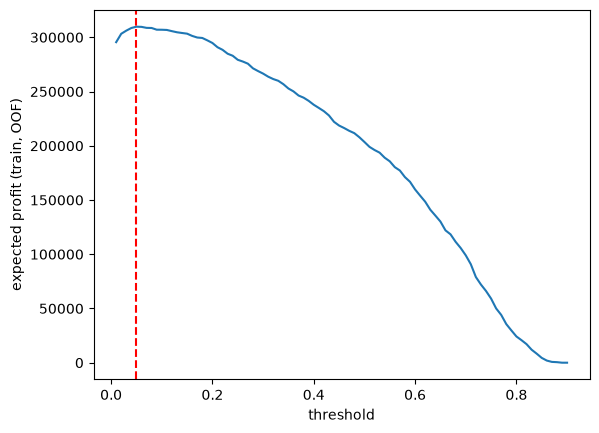

In [4]:
y_arr = y_train.to_numpy()
kw = dict(value=LOSS_IF_CHURN, cost=OFFER_COST, save_rate=SAVE_RATE)

contact_all = expected_profit(y_arr, oof, 0.0, **kw)
contact_none = 0.0
best_profit = max(profits)

print(f"best threshold: {best_t:.2f}")
print(f"profit: nobody {contact_none:.0f}, everyone {contact_all:.0f}, model {best_profit:.0f}")
print(f"theoretical threshold c/(p*V): {OFFER_COST / (SAVE_RATE * LOSS_IF_CHURN):.3f}")

plt.plot(thresholds, profits)
plt.axvline(best_t, color="r", linestyle="--")
plt.xlabel("threshold")
plt.ylabel("expected profit (train, OOF)")
plt.savefig(FIG_DIR / "profit_by_threshold.png", dpi=150, bbox_inches="tight")
plt.show()

# Sensitivity analysis

## Model gain vs the best simple strategy

In [5]:
costs = [10, 20, 40, 80]
save_rates = [0.1, 0.3, 0.5]

rows = []
for c in costs:
    for p in save_rates:
        kw = dict(value=LOSS_IF_CHURN, cost=c, save_rate=p)
        prof = [expected_profit(y_arr, oof, t, **kw) for t in thresholds]
        model_profit = max(max(prof), 0.0)
        everyone = expected_profit(y_arr, oof, 0.0, **kw)
        rows.append({
            "cost": c,
            "save_rate": p,
            "best_threshold": round(thresholds[int(np.argmax(prof))], 2),
            "model": round(model_profit),
            "everyone": round(everyone),
            "gain_vs_simple": round(model_profit - max(everyone, 0.0)),
        })

sens = pd.DataFrame(rows)
sens.pivot(index="cost", columns="save_rate", values="gain_vs_simple")

save_rate,0.1,0.3,0.5
cost,,,
10,14641,7979,6510
20,42794,23289,18005
40,25022,70118,50525
80,82,143253,155010


## Best threshold

In [6]:
sens.pivot(index="cost", columns="save_rate", values="best_threshold")

save_rate,0.1,0.3,0.5
cost,,,
10,0.11,0.04,0.02
20,0.20,0.05,0.04
40,0.49,0.18,0.08
80,0.85,0.33,0.18


# Final evaluation on the test set

In [7]:
model.fit(X_train, y_train)
proba_test = model.predict_proba(X_test)[:, 1]
y_test_arr = y_test.to_numpy()
kw = dict(value=LOSS_IF_CHURN, cost=OFFER_COST, save_rate=SAVE_RATE)

contact = proba_test >= best_t
n = len(y_test_arr)

print(f"ROC-AUC: {roc_auc_score(y_test_arr, proba_test):.3f}")
print(f"threshold {best_t:.2f}: recall {recall_score(y_test_arr, contact):.3f}, "
      f"precision {precision_score(y_test_arr, contact):.3f}, contacted {contact.mean():.1%}")

for name, t in [("nobody", None), ("everyone", 0.0), ("model", best_t)]:
    profit = 0.0 if t is None else expected_profit(y_test_arr, proba_test, t, **kw)
    print(f"{name:9s} profit: {profit:8.0f}   per 1000 customers: {profit / n * 1000:8.0f}")

ROC-AUC: 0.847
threshold 0.05: recall 0.987, precision 0.369, contacted 71.0%
nobody    profit:        0   per 1000 customers:        0
everyone  profit:    71678   per 1000 customers:    50872
model     profit:    78523   per 1000 customers:    55730


# Conclusions

- The profit-maximizing threshold on out-of-fold train predictions is 0.05, close to the theoretical break-even c / (p x V) = 0.075.
- With the simulated assumptions (loss 890, offer cost 20, 30% saved), the model contacts 71% of test customers (recall 0.987, precision 0.369).
- Expected profit per 1000 test customers: nobody 0, everyone 50872, model 55730, about +9.5% over contacting everyone.
- The value of the model depends on the cost of the offer: its gain over the best simple strategy grows when the offer is expensive (train set: about 8k at c=10 to about 143k at c=80, p=0.3). When the offer is cheap, contacting almost everyone is already close to optimal.
- All money values are simulated from three assumed numbers; the real save rate can only be measured with an A/B test.